В цьому ноутбуці відбуваєтся тестування рандомних активів на рандомному проміжку часу. Метою є візуальна перевірка коректність роботи бектест алгоритму

In [1]:
import os
os.chdir("..")

In [2]:
import pandas as pd
import numpy as np
import random

from app import BacktestDCA
from ploter import ploter

/Users/aleksejkitajskij/Desktop/DCA/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# stocks

In [3]:
df_stocks = pd.read_csv("data/test_crypto.csv", index_col=0, parse_dates=True)
df_stocks

,BTC,ETH,SOL,XRP,ADA,DOT,LINK,XLM,XMR
Date,,,,,,,,,
2014-09-17,457.334015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-18,424.440002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-19,394.795990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-20,408.903992,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-21,398.821014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
2026-10-19,81853.539062,2404.815186,104.926231,1.302713,0.217995,1.153126,12.043903,0.177571,605.426392
2026-10-20,82941.000000,2446.730713,106.422340,1.334452,0.223782,1.149771,12.320927,0.181960,600.929504
2026-10-21,84011.968750,2470.766113,106.793655,1.363619,0.224979,1.141323,12.484719,0.183488,622.434082


In [4]:
sequence_length = 365 * 4

In [5]:
token_num = 5

random_token = random.sample(df_stocks.columns.tolist(), token_num)
random_token

['LINK', 'ETH', 'ADA', 'SOL', 'XLM']

In [6]:
# strategy={"minimum_profit": np.inf, "minimum_loss": -np.inf}
strategy={}

12:49:48 - cmdstanpy - INFO - Chain [1] start processing
12:49:49 - cmdstanpy - INFO - Chain [1] done processing


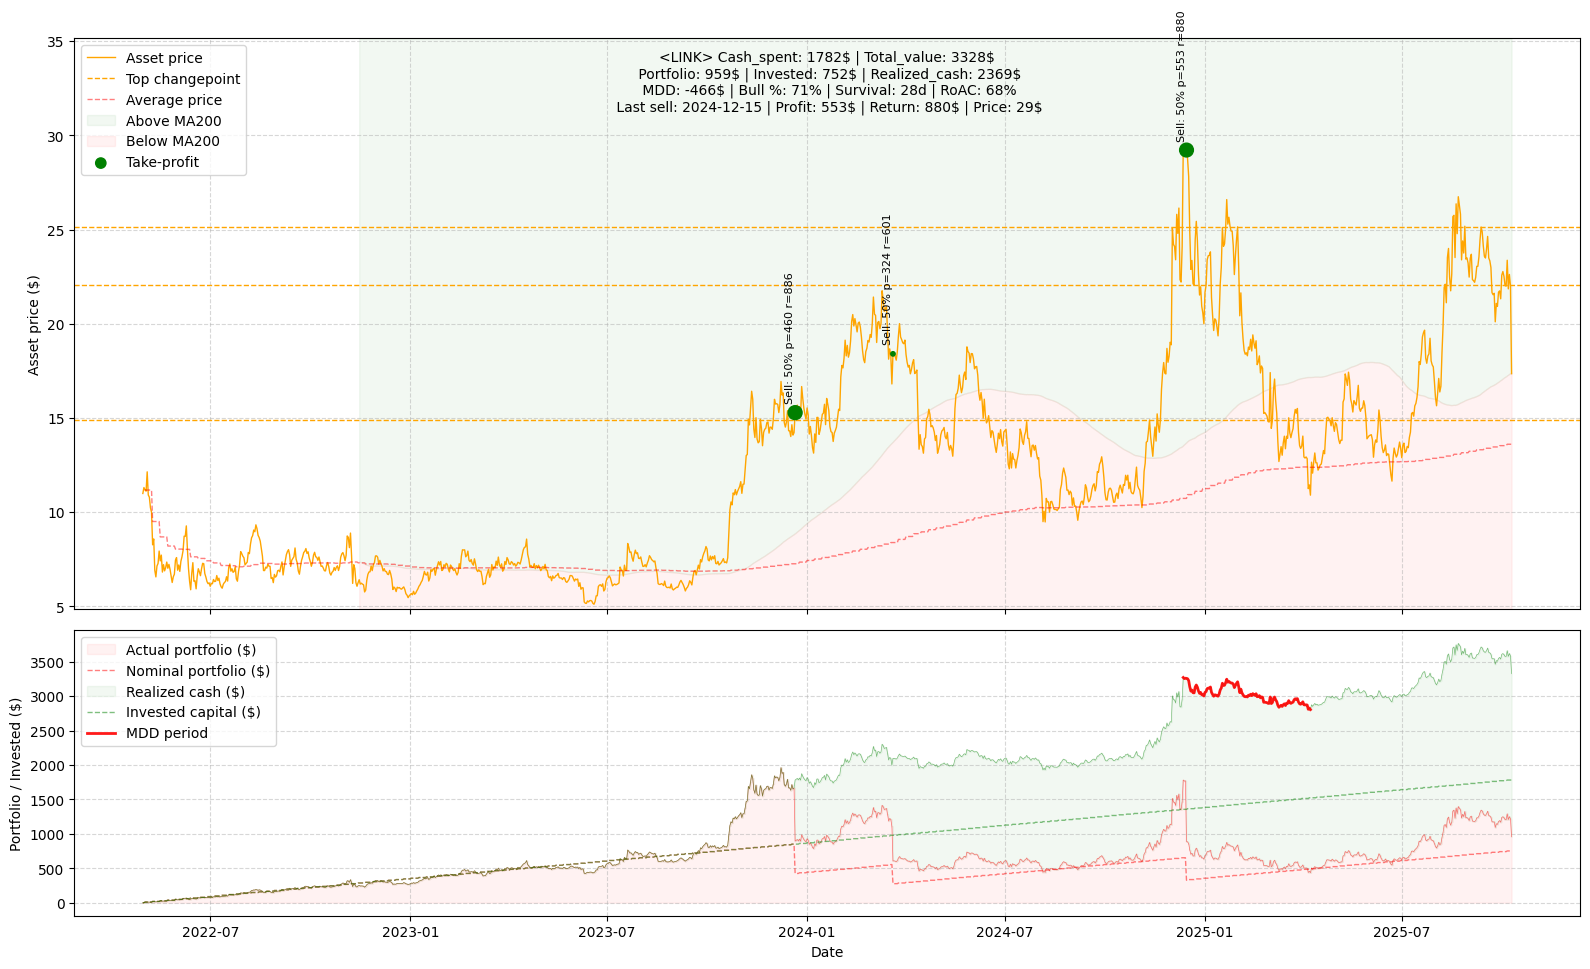

12:49:49 - cmdstanpy - INFO - Chain [1] start processing
12:49:49 - cmdstanpy - INFO - Chain [1] done processing


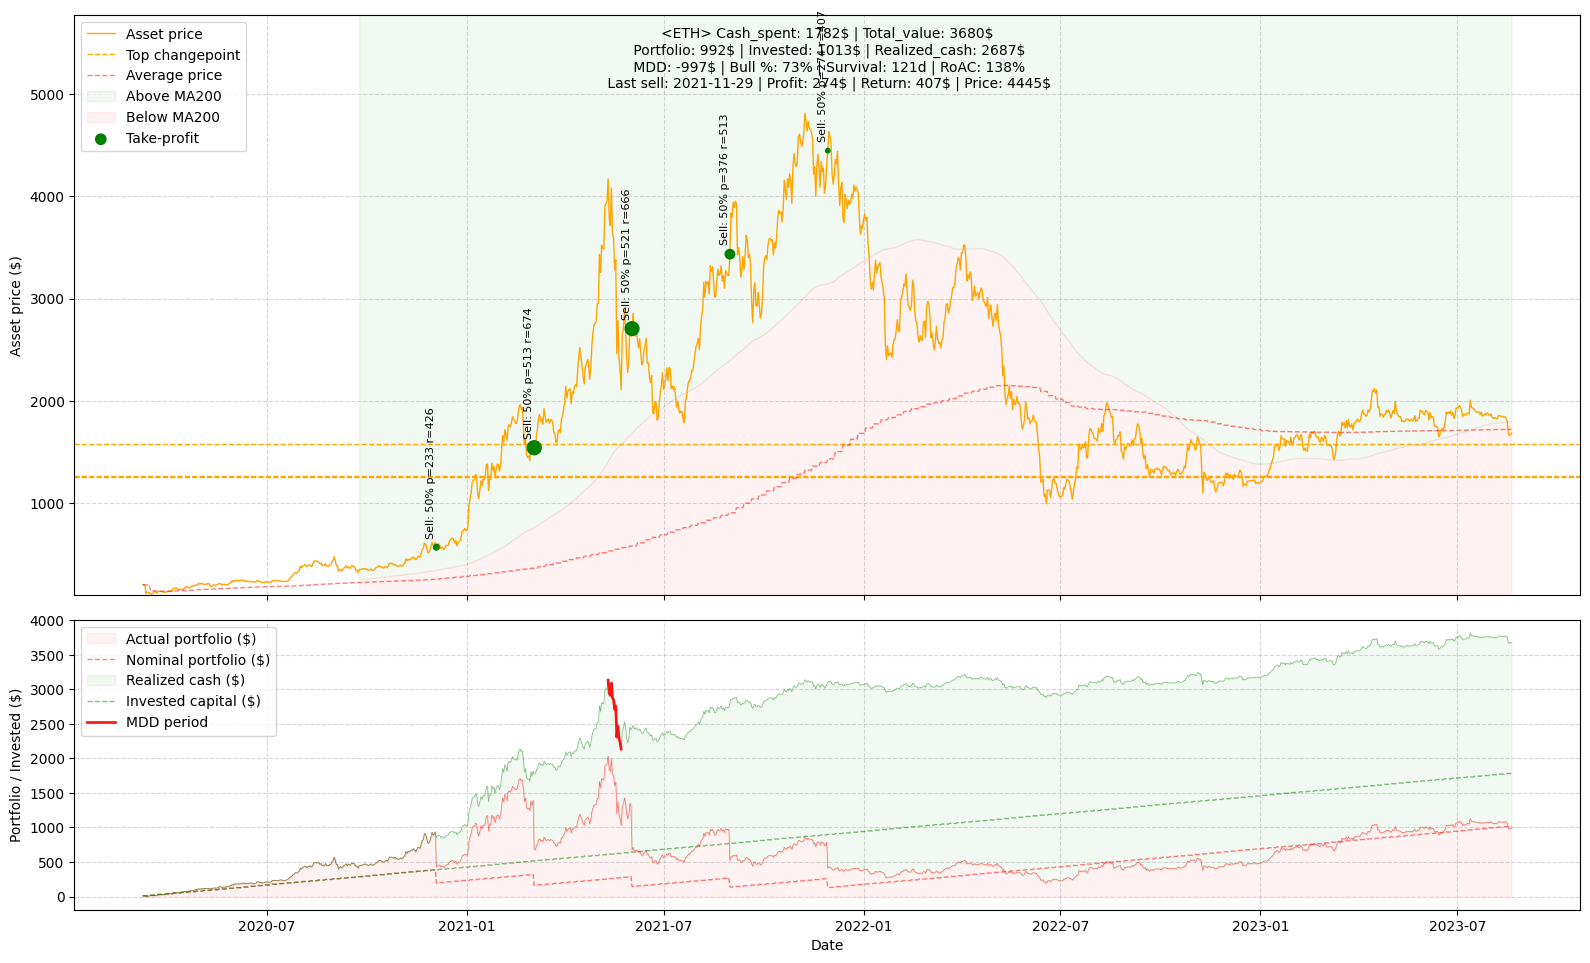

12:49:50 - cmdstanpy - INFO - Chain [1] start processing
12:49:50 - cmdstanpy - INFO - Chain [1] done processing


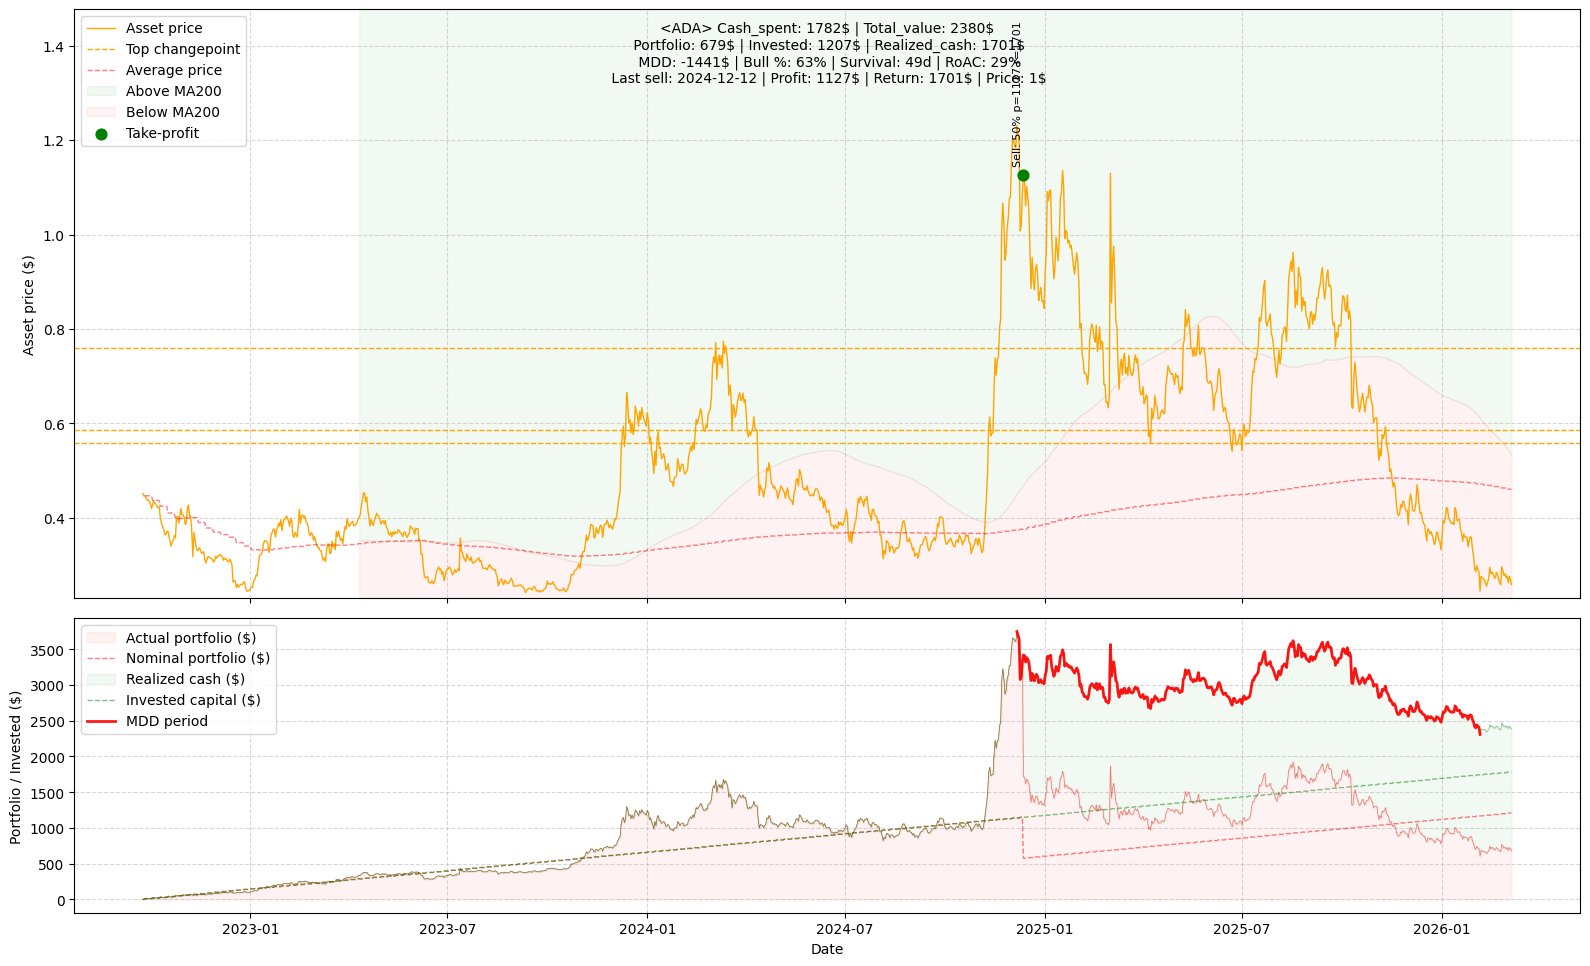

12:49:50 - cmdstanpy - INFO - Chain [1] start processing
12:49:50 - cmdstanpy - INFO - Chain [1] done processing


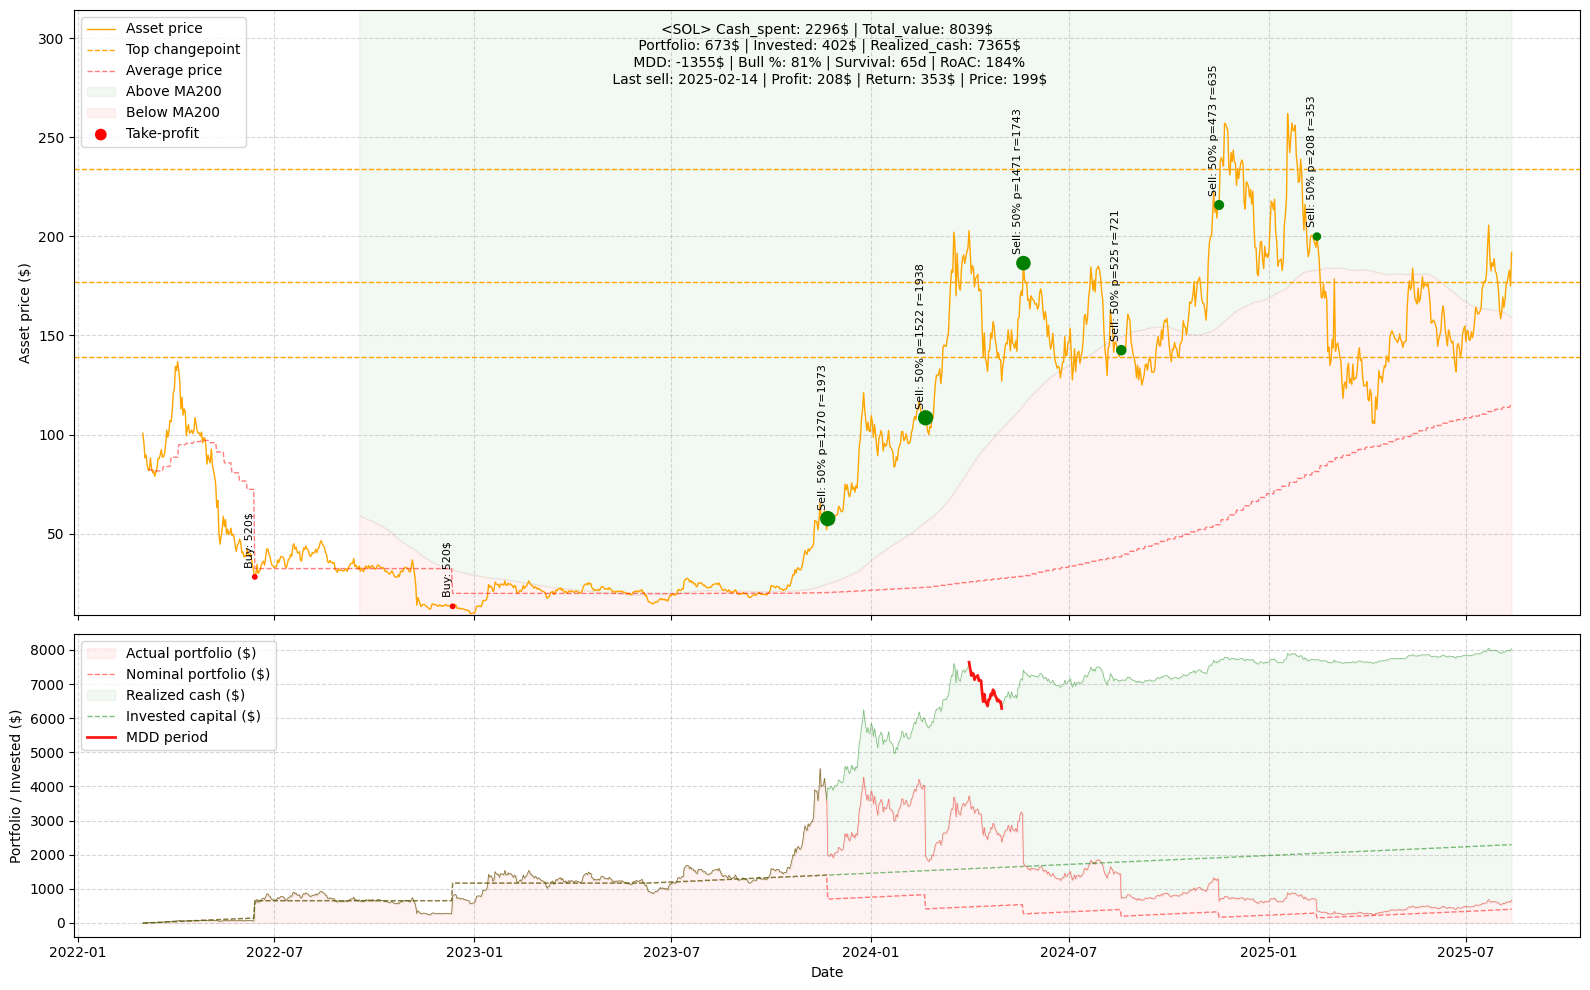

12:49:51 - cmdstanpy - INFO - Chain [1] start processing
12:49:51 - cmdstanpy - INFO - Chain [1] done processing


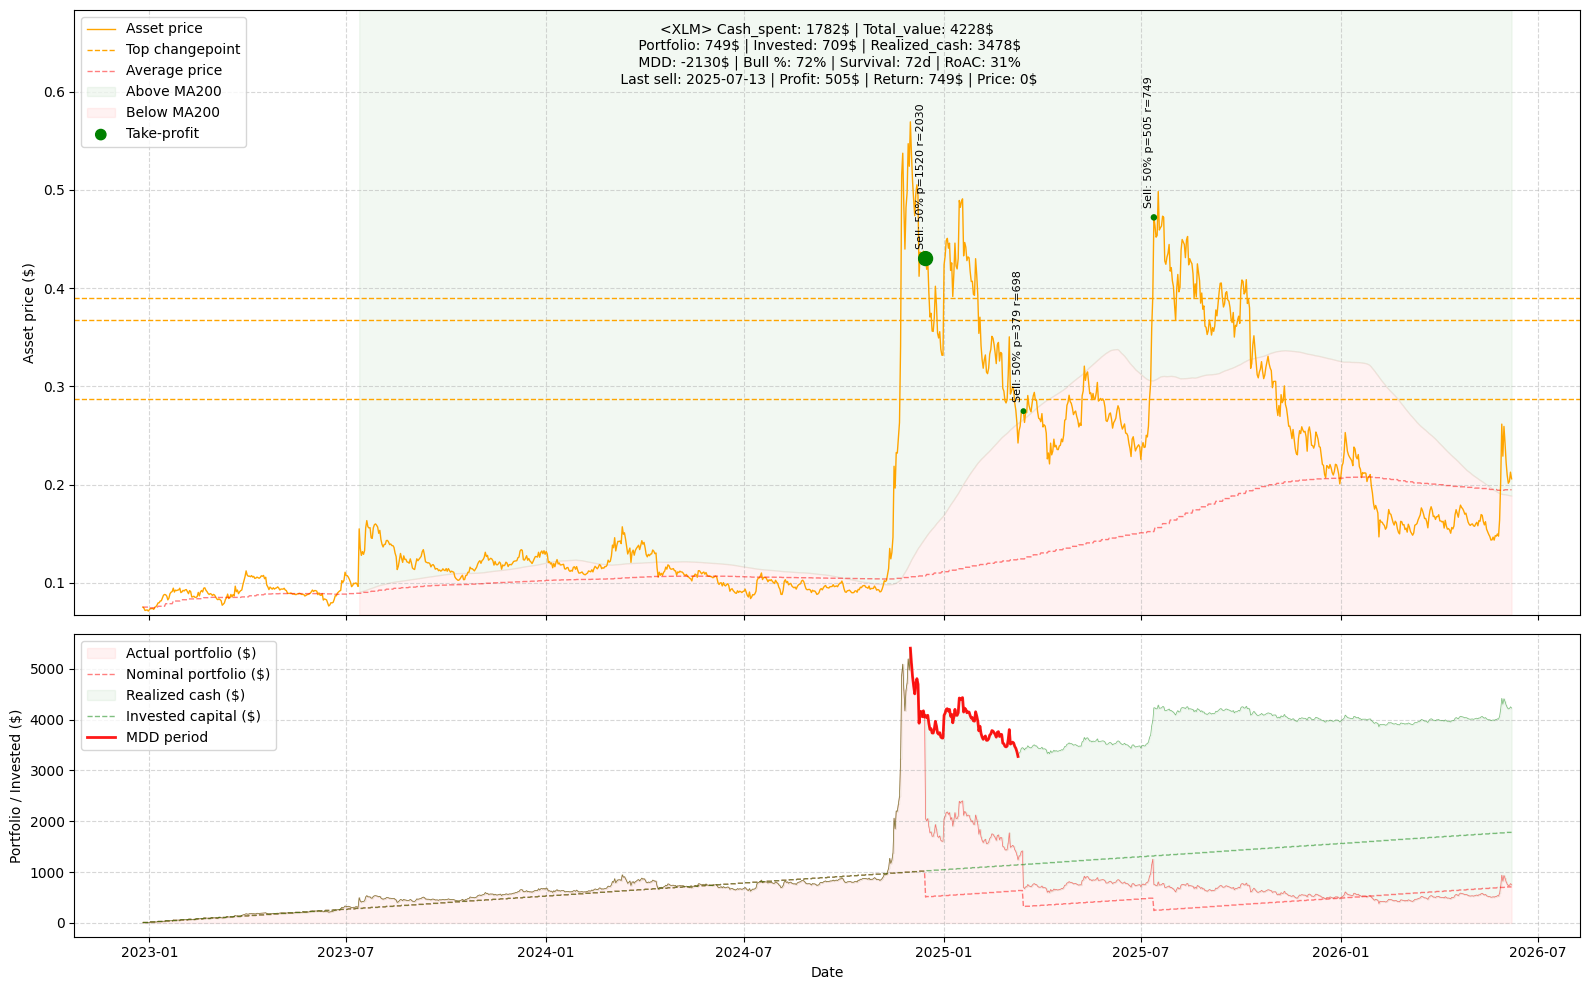

Total invested: $9424.00
Total return: $17600.00
Total value: $21655.00


In [7]:
total_invested = 0
total_profit = 0
total_return = 0
total_value = 0

for stock in random_token:

    prices = df_stocks[stock]
    prices = prices.dropna()
    start = random.randint(0, len(prices) - sequence_length)
    prices = prices.iloc[start:start + sequence_length]
    prices = prices.iloc[200:]

    try:
        bt = BacktestDCA(
        target=stock,
        prices=prices,
        strategy=strategy
        )
        result, metrics = bt.run()
        ploter(metrics=metrics, history=result)
    except Exception as e:
        print(f"Error backtesting {stock}: {e}")
        continue

    total_invested += metrics['Cash_spent']
    total_return += metrics['Realized_cash']
    total_value += metrics['Total_value']

print(f"Total invested: ${total_invested:.2f}")
print(f"Total return: ${total_return:.2f}")
print(f"Total value: ${total_value:.2f}")

In [8]:
result

,Price,Portfolio_qty,Cost_basis,Cash_spent,Profit,Returns,Realized_cash,Trigger_msg,Portfolio,Average_price,Total_value
Date,,,,,,,,,,,
2022-12-26,0.075192,131.662948,9.9000,9.9,0.0,0.0,0.000000,,9.900000,0.075192,9.900000
2022-12-27,0.074137,131.662948,9.9000,9.9,0.0,0.0,0.000000,,9.761096,0.075192,9.761096
2022-12-28,0.071779,131.662948,9.9000,9.9,0.0,0.0,0.000000,,9.450634,0.075192,9.450634
2022-12-29,0.072032,131.662948,9.9000,9.9,0.0,0.0,0.000000,,9.483945,0.075192,9.483945
2022-12-30,0.072343,131.662948,9.9000,9.9,0.0,0.0,0.000000,,9.524893,0.075192,9.524893
...,...,...,...,...,...,...,...,...,...,...,...
2026-06-03,0.209359,3641.660235,709.0875,1782.0,0.0,0.0,3478.508565,,762.414364,0.194715,4240.922929
2026-06-04,0.201324,3641.660235,709.0875,1782.0,0.0,0.0,3478.508565,,733.153609,0.194715,4211.662174
2026-06-05,0.203077,3641.660235,709.0875,1782.0,0.0,0.0,3478.508565,,739.537448,0.194715,4218.046013


In [9]:
(result['Portfolio'] > 0).sum()

np.int64(1260)

In [10]:
metrics

{'Target': 'XLM',
 'Cash_spent': 1782,
 'Realized_cash': 3478,
 'Portfolio': 749,
 'Invested': 709,
 'Total_value': 4228,
 'Bull_history': 72,
 'MDD': -2130,
 'MA200_survival_days': 72.19999999999999,
 'RoAC': 31}